## Making traindata - 배경부분 위치 저장후 보간수행 후 클리핑 후 znorm


In [132]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import pandas as pd
import numpy as np
import scipy.signal as signal
import scipy.interpolate as interp
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
# --- 2. GT 신호 필터링용 함수 (기존 코드 활용) ---
# def z_norm_vid(win_video, fill_value = -3.0) :


def butter_bandpass_filter(data, lowcut, highcut, fs, order=2):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    y = signal.filtfilt(b, a, data)
    return y

def z_norm(data):
    return (data - np.mean(data, axis = 0)) / (np.std(data, axis = 0) + 1e-8)


def z_norm_vid(win_video_interpolated, bg_fill_value=-3.0):
    """
    1번 관점 적용: 보간 직후 진짜 배경 위치를 먼저 찾고, 클리핑과 정규화를 수행하는 함수
    """
    # 1. 배경 위치 파악 (클리핑 전!)
    # 절대값이 아주 작은(1e-5 이하) 픽셀만 '진짜 배경'으로 간주합니다.
    # 이렇게 하면 보간 오차로 인해 -0.5로 튄 피부 경계선은 배경이 아닌 유효 픽셀로 살아남습니다.
    is_background = np.abs(win_video_interpolated) <= 1e-5
    is_valid = ~is_background
    
    # 2. 클리핑 수행
    # 이제 배경 위치를 안전하게 기억해 뒀으니, 외삽 노이즈를 0.0 ~ 1.0으로 잘라냅니다.
    win_video_clipped = np.clip(win_video_interpolated, 0.0, 1.0)
    
    # 3. 유효 픽셀(피부)만 모아서 Z-norm 통계량 계산
    valid_pixels = win_video_clipped[is_valid]
    
    # 만약 유효 픽셀이 하나도 없다면 전체를 배경값으로 반환 (예외 처리)
    if len(valid_pixels) == 0:
        return np.full_like(win_video_clipped, bg_fill_value)
        
    global_mean = np.mean(valid_pixels)
    global_std = np.std(valid_pixels) + 1e-8
    
    # 4. 클리핑된 전체 비디오에 대해 Z-norm 수행
    norm_video = (win_video_clipped - global_mean) / global_std
    
    # 5. 처음에 기억해 둔 '진짜 배경' 위치에만 -3.0 덮어쓰기
    norm_video[is_background] = bg_fill_value 
    
    return norm_video

# --- 3. 핵심 윈도우 처리 및 보간 함수 ---
def process_video_and_gt_windows(video_data, gt_ppg, sub_valid, window_size=900, max_gap_threshold=30):
    n_samples = len(video_data)
    n_windows = n_samples // window_size
    
    valid_vid_list = []
    valid_gt_list = []
    discarded_indices = []

    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        
        win_video = video_data[start_idx:end_idx].copy()
        win_gt = gt_ppg[start_idx:end_idx].copy()
        win_valid = sub_valid[start_idx:end_idx].copy()
        
        # 결손(Gap) 길이 체크
        is_invalid = ~win_valid
        if np.any(is_invalid):
            condition = np.concatenate(([0], is_invalid, [0]))
            idx = np.flatnonzero(condition[1:] != condition[:-1])
            gap_lengths = idx[1::2] - idx[::2]
            max_gap = gap_lengths.max() if len(gap_lengths) > 0 else 0
        else:
            max_gap = 0
            
        # 임계치 30프레임(1초) 이상 시 폐기
        if max_gap >= max_gap_threshold:
            discarded_indices.append(i)
            continue
            
        try:
            # 보간(Interpolation) 수행
            if max_gap > 0:
                valid_idx = np.where(win_valid)[0]
                all_idx = np.arange(window_size)
                
                if len(valid_idx) > 1:
                    # 다차원 영상 PCHIP 보간
                    win_video = interp.pchip_interpolate(valid_idx, win_video[valid_idx], all_idx, axis=0)
                    

                else:
                    discarded_indices.append(i)
                    continue
            
            # --- 영상 전처리 ---
            
            #win_video_norm = z_norm_vid(win_video)
            
            # --- GT 전처리 ---
            # GT는 Detrend, Bandpass(0.75~2.5Hz), Z-norm 빡빡하게 적용
            detrend_gt = signal.detrend(win_gt)
            filter_gt = butter_bandpass_filter(detrend_gt, 0.75, 2.5, fs_video, order=2)
            win_gt_norm = z_norm(filter_gt)
            
            # 유효 리스트에 추가
            valid_vid_list.append(win_video)
            valid_gt_list.append(win_gt_norm)
            
        except Exception as e:
            print(f'Window {i} Error : {e}')
            discarded_indices.append(i)

    return valid_vid_list, valid_gt_list, discarded_indices



In [137]:
shift_frames = 400
fs_video = 30.0
fs_ppg = 500.0

# --- 1. 설정 및 파라미터 ---
people = ['A001_20250609', 'A002_20250609', 'A004_20250610', 'A005_20250611', 'A006_20250611', 
          'A007_20250612', 'A008_20250612', 'B001_20250623', 'B002_20250623', 'B003_20250624', 
          'B004_20250624', 'B005_20250625', 'B008_20250627', 'C001_20250701', 'C002_20250703', 'C003_20250702']

people_ppg = sorted([k.replace('_20', '_') for k in people])

preprocess_result_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
ppg_cut_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_cut_final' # 실제 GT 경로로 수정 필요
final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_for_dl' # 최종 저장 폴더 (미리 생성 필요)

os.makedirs(final_save_dir, exist_ok=True)



# --- 4. 메인 파이프라인 ---
for subject_id, ppg_id in zip(people, people_ppg):
    print(f"\n--- Processing {subject_id} ---")
    
    try:
        # 1. 이전 단계에서 만든 H5 비디오 데이터 로드
        h5_video_path = os.path.join(preprocess_result_dir, f'registration_video_[{subject_id}].h5')
        with h5py.File(h5_video_path, 'r') as f_v:
            video_data = f_v['nir_uv_data'][:]
            sub_valid = f_v['valid_mask'][:]
            
        # 2. GT PPG CSV 로드 (이 경로는 실제 환경에 맞춰 수정해 주세요)
        gt_csv_path = os.path.join(ppg_cut_dir, f'{ppg_id}.csv')
        ppg_cut = pd.read_csv(gt_csv_path).values.flatten()
        
        # 3. 싱크 조절 (400프레임 지연 반영)
        ppg_shift_samples = int(round((shift_frames / fs_video) * fs_ppg))
        
        ppg_trimmed = ppg_cut[ppg_shift_samples:]
        video_trimmed = video_data[:-shift_frames]
        sub_valid_trimmed = sub_valid[:-shift_frames]
        
        # GT 다운샘플링
        ppg_downsampled = signal.resample(ppg_trimmed, len(video_trimmed))
        
        # 4. 윈도우 분할 및 보간
        valid_vid_list, valid_gt_list, discarded = process_video_and_gt_windows(
            video_data=video_trimmed,
            gt_ppg=ppg_downsampled,
            sub_valid=sub_valid_trimmed,
            window_size=900,
            max_gap_threshold=30
        )
        
        if len(valid_vid_list) == 0:
            print(f"[{subject_id}] 유효한 윈도우가 없습니다. 건너뜁니다.")
            continue
            
        # 5. Array 형태로 묶기 (DataLoader 최적화)
        video_array = np.stack(valid_vid_list) # Shape: (유효 윈도우 수, 900, 64, 64)
        gt_array = np.stack(valid_gt_list)     # Shape: (유효 윈도우 수, 900)
        
        # 6. 최종 H5 파일 저장
        final_h5_path = os.path.join(final_save_dir, f'final_dataset_{subject_id}.h5')
        with h5py.File(final_h5_path, 'w') as f_out:
            f_out.create_dataset('video', data=video_array, chunks=True, compression='gzip', compression_opts=4)
            f_out.create_dataset('gt_ppg', data=gt_array, chunks=True, compression='gzip', compression_opts=4)
            
        print(f"[{subject_id}] 완료! 총 {len(valid_vid_list)}개 윈도우 저장됨. (폐기: {len(discarded)}개)")
        print(f"  -> Video Shape: {video_array.shape}, GT Shape: {gt_array.shape}")
        
    except Exception as e:
        print(f"[{subject_id}] 처리 중 오류 발생: {e}")


--- Processing A001_20250609 ---
[A001_20250609] 완료! 총 128개 윈도우 저장됨. (폐기: 1개)
  -> Video Shape: (128, 900, 64, 64), GT Shape: (128, 900)

--- Processing A002_20250609 ---
[A002_20250609] 완료! 총 130개 윈도우 저장됨. (폐기: 6개)
  -> Video Shape: (130, 900, 64, 64), GT Shape: (130, 900)

--- Processing A004_20250610 ---
[A004_20250610] 완료! 총 135개 윈도우 저장됨. (폐기: 1개)
  -> Video Shape: (135, 900, 64, 64), GT Shape: (135, 900)

--- Processing A005_20250611 ---
[A005_20250611] 완료! 총 85개 윈도우 저장됨. (폐기: 58개)
  -> Video Shape: (85, 900, 64, 64), GT Shape: (85, 900)

--- Processing A006_20250611 ---
[A006_20250611] 완료! 총 125개 윈도우 저장됨. (폐기: 0개)
  -> Video Shape: (125, 900, 64, 64), GT Shape: (125, 900)

--- Processing A007_20250612 ---
[A007_20250612] 완료! 총 88개 윈도우 저장됨. (폐기: 55개)
  -> Video Shape: (88, 900, 64, 64), GT Shape: (88, 900)

--- Processing A008_20250612 ---
[A008_20250612] 완료! 총 76개 윈도우 저장됨. (폐기: 63개)
  -> Video Shape: (76, 900, 64, 64), GT Shape: (76, 900)

--- Processing B001_20250623 ---
[B001_

## checking datavalues

In [125]:
shift_frames = 400
fs_video = 30.0
fs_ppg = 500.0

# --- 1. 설정 및 파라미터 ---
people = ['A001_20250609', 'A002_20250609', 'A004_20250610', 'A005_20250611', 'A006_20250611', 
          'A007_20250612', 'A008_20250612', 'B001_20250623', 'B002_20250623', 'B003_20250624', 
          'B004_20250624', 'B005_20250625', 'B008_20250627', 'C001_20250701', 'C002_20250703', 'C003_20250702']

people_ppg = sorted([k.replace('_20', '_') for k in people])

preprocess_result_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/preprocess_result'
ppg_cut_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/ppg_cut_final' # 실제 GT 경로로 수정 필요
final_save_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/data_for_dl' # 최종 저장 폴더 (미리 생성 필요)

up_

for i in range(len(people))
    idx = i

    print(f"\n--- Processing {people[idx]} ---")


    # 1. 이전 단계에서 만든 H5 비디오 데이터 로드
    h5_video_path = os.path.join(preprocess_result_dir, f'registration_video_[{people[idx]}].h5')
    with h5py.File(h5_video_path, 'r') as f_v:
        video_data = f_v['nir_uv_data'][:]
        sub_valid = f_v['valid_mask'][:]
        
    # 2. GT PPG CSV 로드 (이 경로는 실제 환경에 맞춰 수정해 주세요)
    gt_csv_path = os.path.join(ppg_cut_dir, f'{people_ppg[idx]}.csv')
    ppg_cut = pd.read_csv(gt_csv_path).values.flatten()

    # 3. 싱크 조절 (400프레임 지연 반영)
    ppg_shift_samples = int(round((shift_frames / fs_video) * fs_ppg))

    ppg_trimmed = ppg_cut[ppg_shift_samples:]
    video_trimmed = video_data[:-shift_frames]
    sub_valid_trimmed = sub_valid[:-shift_frames]

    # GT 다운샘플링
    ppg_downsampled = signal.resample(ppg_trimmed, len(video_trimmed))

    # 4. 윈도우 분할 및 보간
    valid_vid_list, valid_gt_list, discarded = process_video_and_gt_windows(
        video_data=video_trimmed,
        gt_ppg=ppg_downsampled,
        sub_valid=sub_valid_trimmed,
        window_size=900,
        max_gap_threshold=30
    )

    print(len(valid_vid_list))
        for i in range(len(valid_vid_list)) :
        


--- Processing A002_20250609 ---
130


In [147]:
# interpolation이후 값체크
for i in range(len(valid_vid_list)) :
    print(f"{'='*50}  window : {i} {'='*50}" )
    print(f"  - Min: {np.min(valid_vid_list[i]):.4f} | Max: {np.max(valid_vid_list[i]):.4f}")
    print(f"  - Mean: {np.mean(valid_vid_list[i]):.4f} | Std: {np.std(valid_vid_list[i]):.4f}")
    print('='*100)

==================================================  window : 0 ==================================================
  - Min: 0.0000 | Max: 0.9649
  - Mean: 0.0553 | Std: 0.1064
==================================================  window : 1 ==================================================
  - Min: 0.0000 | Max: 0.5294
  - Mean: 0.0647 | Std: 0.1128
==================================================  window : 2 ==================================================
  - Min: 0.0000 | Max: 0.5274
  - Mean: 0.0668 | Std: 0.1151
==================================================  window : 3 ==================================================
  - Min: 0.0000 | Max: 0.5324
  - Mean: 0.0675 | Std: 0.1168
==================================================  window : 4 ==================================================
  - Min: 0.0000 | Max: 0.5897
  - Mean: 0.0669 | Std: 0.1166
==================================================  window : 5 ==================================================
  - Min: 0.

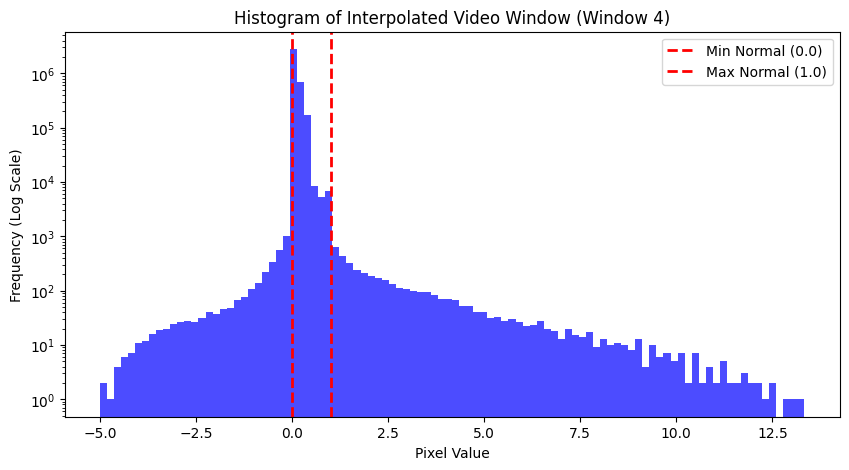

In [148]:
rr = valid_vid_list[63]
plt.figure(figsize=(10, 5))
# flatten()을 통해 1차원으로 펴서 전체 픽셀 값의 분포를 확인합니다.
plt.hist(rr.flatten(), bins=100, color='blue', alpha=0.7)
plt.axvline(0.0, color='red', linestyle='dashed', linewidth=2, label='Min Normal (0.0)')
plt.axvline(1.0, color='red', linestyle='dashed', linewidth=2, label='Max Normal (1.0)')
plt.title("Histogram of Interpolated Video Window (Window 4)")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency (Log Scale)")
plt.yscale('log')  # 대부분의 정상 값(0~1)에 가려 튀는 값이 안 보일 수 있으므로 y축을 로그 스케일로 설정
plt.legend()
plt.show()

총 7865개의 픽셀에서 값이 튀었습니다 (0미만 또는 1초과).

[튀는 값이 많이 발생한 프레임 Top 5]
 - Frame 0 : 406개의 픽셀 이상치 발생
 - Frame 1 : 399개의 픽셀 이상치 발생
 - Frame 2 : 393개의 픽셀 이상치 발생
 - Frame 3 : 386개의 픽셀 이상치 발생
 - Frame 4 : 380개의 픽셀 이상치 발생
 - Frame 5 : 373개의 픽셀 이상치 발생
 - Frame 6 : 364개의 픽셀 이상치 발생
 - Frame 7 : 355개의 픽셀 이상치 발생
 - Frame 8 : 344개의 픽셀 이상치 발생
 - Frame 9 : 335개의 픽셀 이상치 발생
 - Frame 10 : 326개의 픽셀 이상치 발생
 - Frame 11 : 319개의 픽셀 이상치 발생
 - Frame 12 : 310개의 픽셀 이상치 발생
 - Frame 13 : 299개의 픽셀 이상치 발생
 - Frame 14 : 292개의 픽셀 이상치 발생
 - Frame 15 : 274개의 픽셀 이상치 발생
 - Frame 16 : 262개의 픽셀 이상치 발생
 - Frame 17 : 246개의 픽셀 이상치 발생
 - Frame 18 : 230개의 픽셀 이상치 발생
 - Frame 19 : 218개의 픽셀 이상치 발생
 - Frame 20 : 210개의 픽셀 이상치 발생
 - Frame 21 : 201개의 픽셀 이상치 발생
 - Frame 22 : 184개의 픽셀 이상치 발생
 - Frame 23 : 171개의 픽셀 이상치 발생
 - Frame 24 : 150개의 픽셀 이상치 발생
 - Frame 25 : 136개의 픽셀 이상치 발생
 - Frame 26 : 123개의 픽셀 이상치 발생
 - Frame 27 : 102개의 픽셀 이상치 발생
 - Frame 28 : 73개의 픽셀 이상치 발생
 - Frame 49 : 4개의 픽셀 이상치 발생


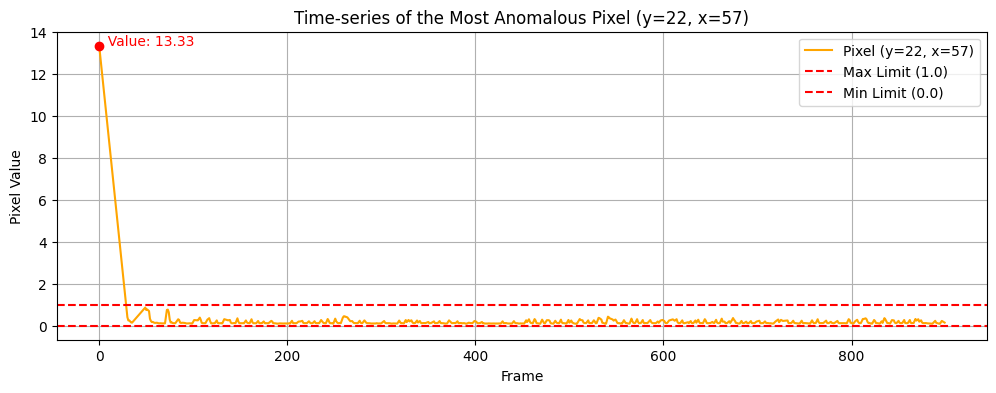

In [149]:
# ==========================================
# 2. 튀는 값(0 미만 또는 1 초과)의 위치 찾기
# ==========================================
# 0.0 보다 작거나 1.0 보다 큰 픽셀의 마스크 생성
abnormal_mask = (rr < 0.0) | (rr > 1.0)
anomalous_indices = np.where(abnormal_mask)

frames = anomalous_indices[0] # 프레임 인덱스 (0~899)
ys = anomalous_indices[1]     # y 좌표 (0~63)
xs = anomalous_indices[2]     # x 좌표 (0~63)

total_abnormal_pixels = np.sum(abnormal_mask)
print(f"총 {total_abnormal_pixels}개의 픽셀에서 값이 튀었습니다 (0미만 또는 1초과).\n")

if total_abnormal_pixels > 0:
    # 어떤 프레임에서 튀는 값이 가장 많이 발생했는지 확인
    unique_frames, counts = np.unique(frames, return_counts=True)
    
    # 튀는 픽셀이 많은 순서대로 정렬
    sorted_idx = np.argsort(-counts)
    
    print("[튀는 값이 많이 발생한 프레임 Top 5]")
    for i in range( len(unique_frames)):
        f = unique_frames[sorted_idx[i]]
        c = counts[sorted_idx[i]]
        print(f" - Frame {f} : {c}개의 픽셀 이상치 발생")
        
    # ==========================================
    # 3. 가장 심하게 튀는 픽셀 하나를 골라 시계열(Time-series) 그래프 그리기
    # ==========================================
    # 값이 가장 큰(또는 가장 작은) 픽셀의 좌표를 찾습니다.
    max_val_idx = np.argmax(rr)
    max_f, max_y, max_x = np.unravel_index(max_val_idx, rr.shape)
    
    plt.figure(figsize=(12, 4))
    # 해당 픽셀의 900프레임 전체 시계열 변화를 그립니다.
    plt.plot(rr[:, max_y, max_x], label=f'Pixel (y={max_y}, x={max_x})', color='orange')
    plt.axhline(1.0, color='red', linestyle='--', label='Max Limit (1.0)')
    plt.axhline(0.0, color='red', linestyle='--', label='Min Limit (0.0)')
    
    # 이상치가 발생한 최대 지점 표시
    plt.scatter([max_f], [rr[max_f, max_y, max_x]], color='red', zorder=5)
    plt.text(max_f, rr[max_f, max_y, max_x], f'  Value: {rr[max_f, max_y, max_x]:.2f}', color='red')

    plt.title(f"Time-series of the Most Anomalous Pixel (y={max_y}, x={max_x})")
    plt.xlabel("Frame")
    plt.ylabel("Pixel Value")
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("이 윈도우에는 0 미만이나 1 초과인 튀는 값이 없습니다.")

In [84]:
max_val_idx = np.argmax(rr)
max_f, max_y, max_x = np.unravel_index(max_val_idx, rr.shape)


(899, 15, 50)

### checking values perframe

In [17]:
train_vid = {}
train_ppg = {}
valid_vid = {}
valid_ppg = {}

for sub_n in train_sub :
    with h5py.File(os.path.join( final_save_dir, sub_n), 'r') as f_v:
        if sub_n[14:18] not in train_vid :
            train_vid[sub_n[14:18]] = ''
            train_ppg[sub_n[14:18]] = ''
        train_vid[sub_n[14:18]] = f_v['video'][:]
        train_ppg[sub_n[14:18]] = f_v['gt_ppg'][:]


for sub_nn in valid_sub :
    with h5py.File(os.path.join( final_save_dir, sub_nn), 'r') as f_v:
        if sub_n[14:18] not in valid_vid :
            valid_vid[sub_nn[14:18]] = ''
            valid_ppg[sub_nn[14:18]] = ''
        valid_vid[sub_nn[14:18]] = f_v['video'][:]
        valid_ppg[sub_nn[14:18]] = f_v['gt_ppg'][:]



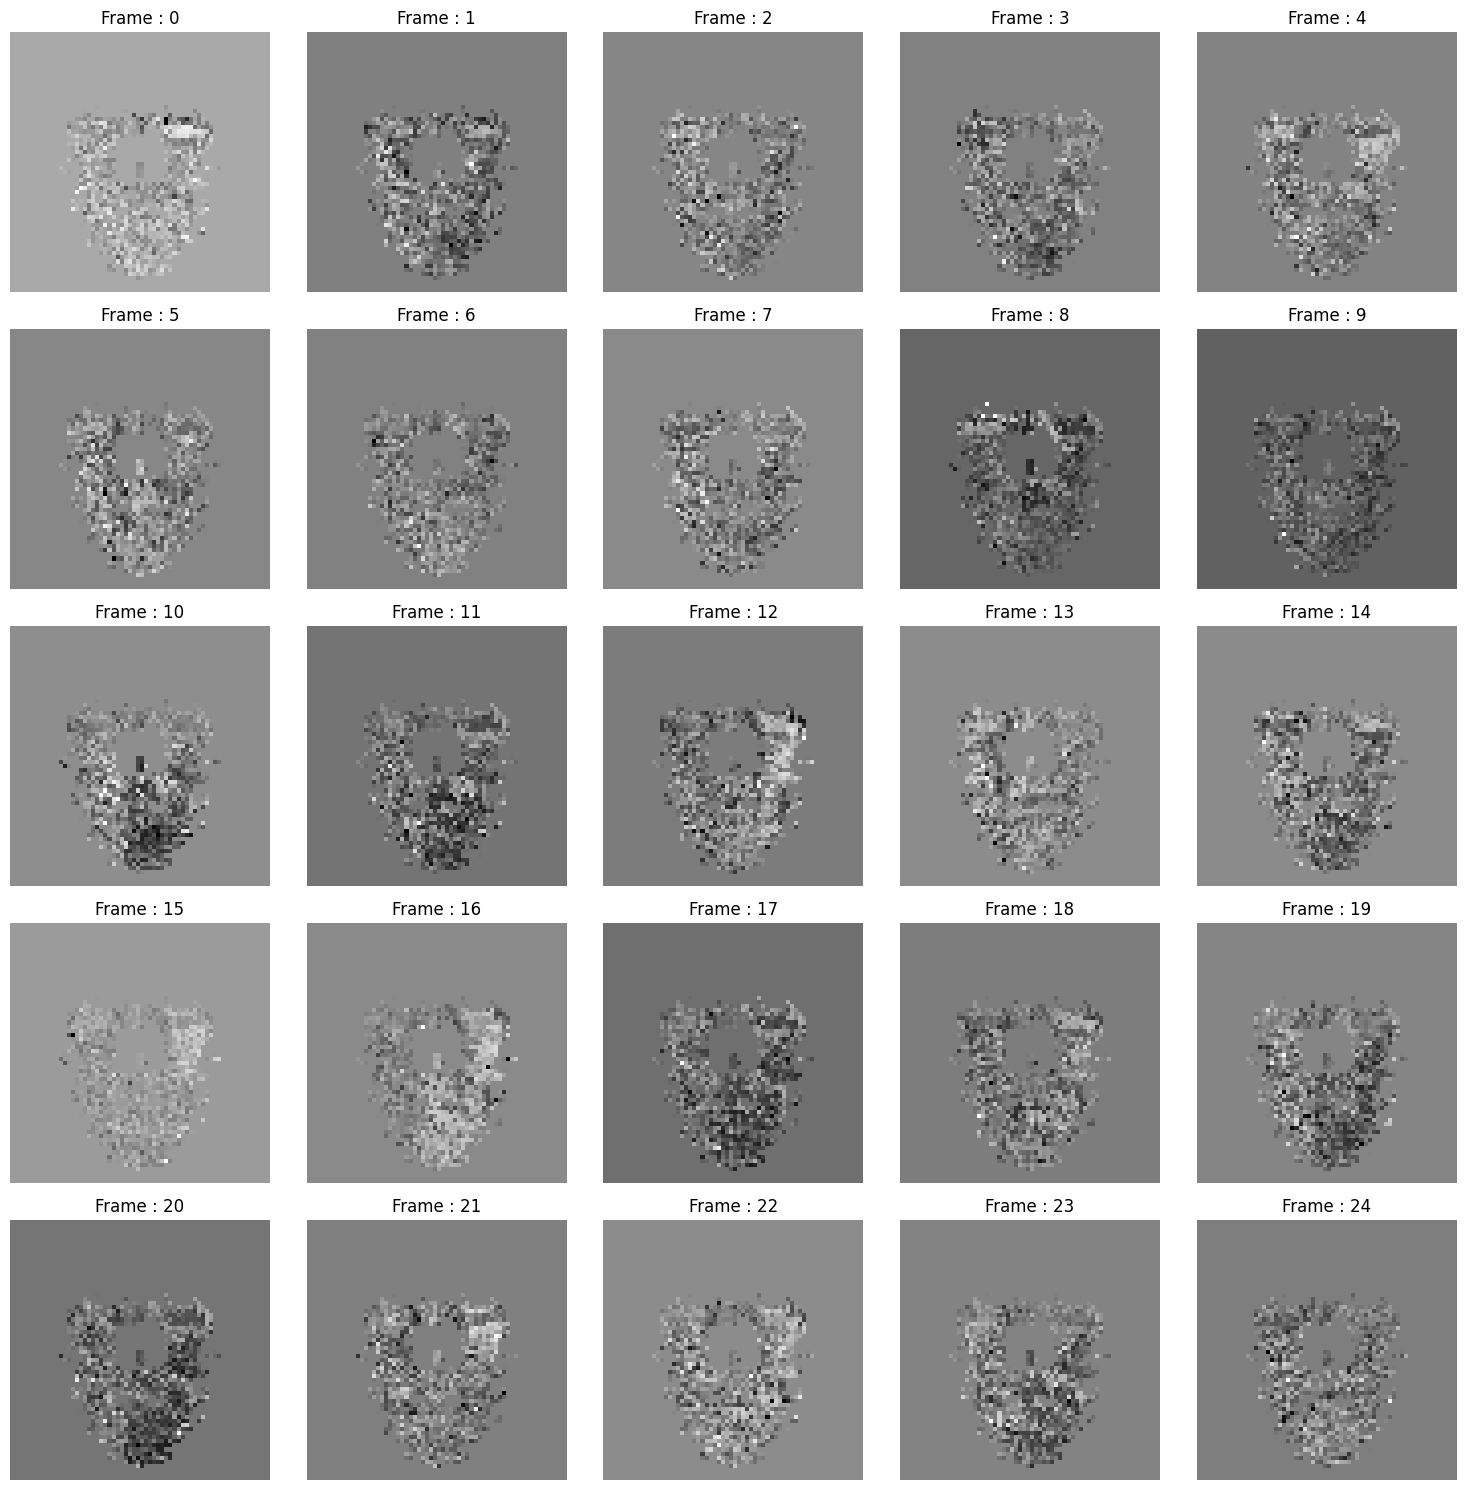

In [26]:
v1 = valid_vid['A004']
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, f in enumerate(v1[54][:25]):
        
    axes[i].imshow(f, cmap='gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


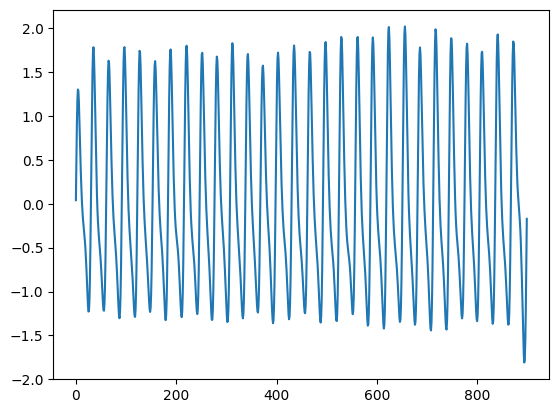

In [37]:
vp1 = valid_ppg['A004']
plt.plot(vp1[0])


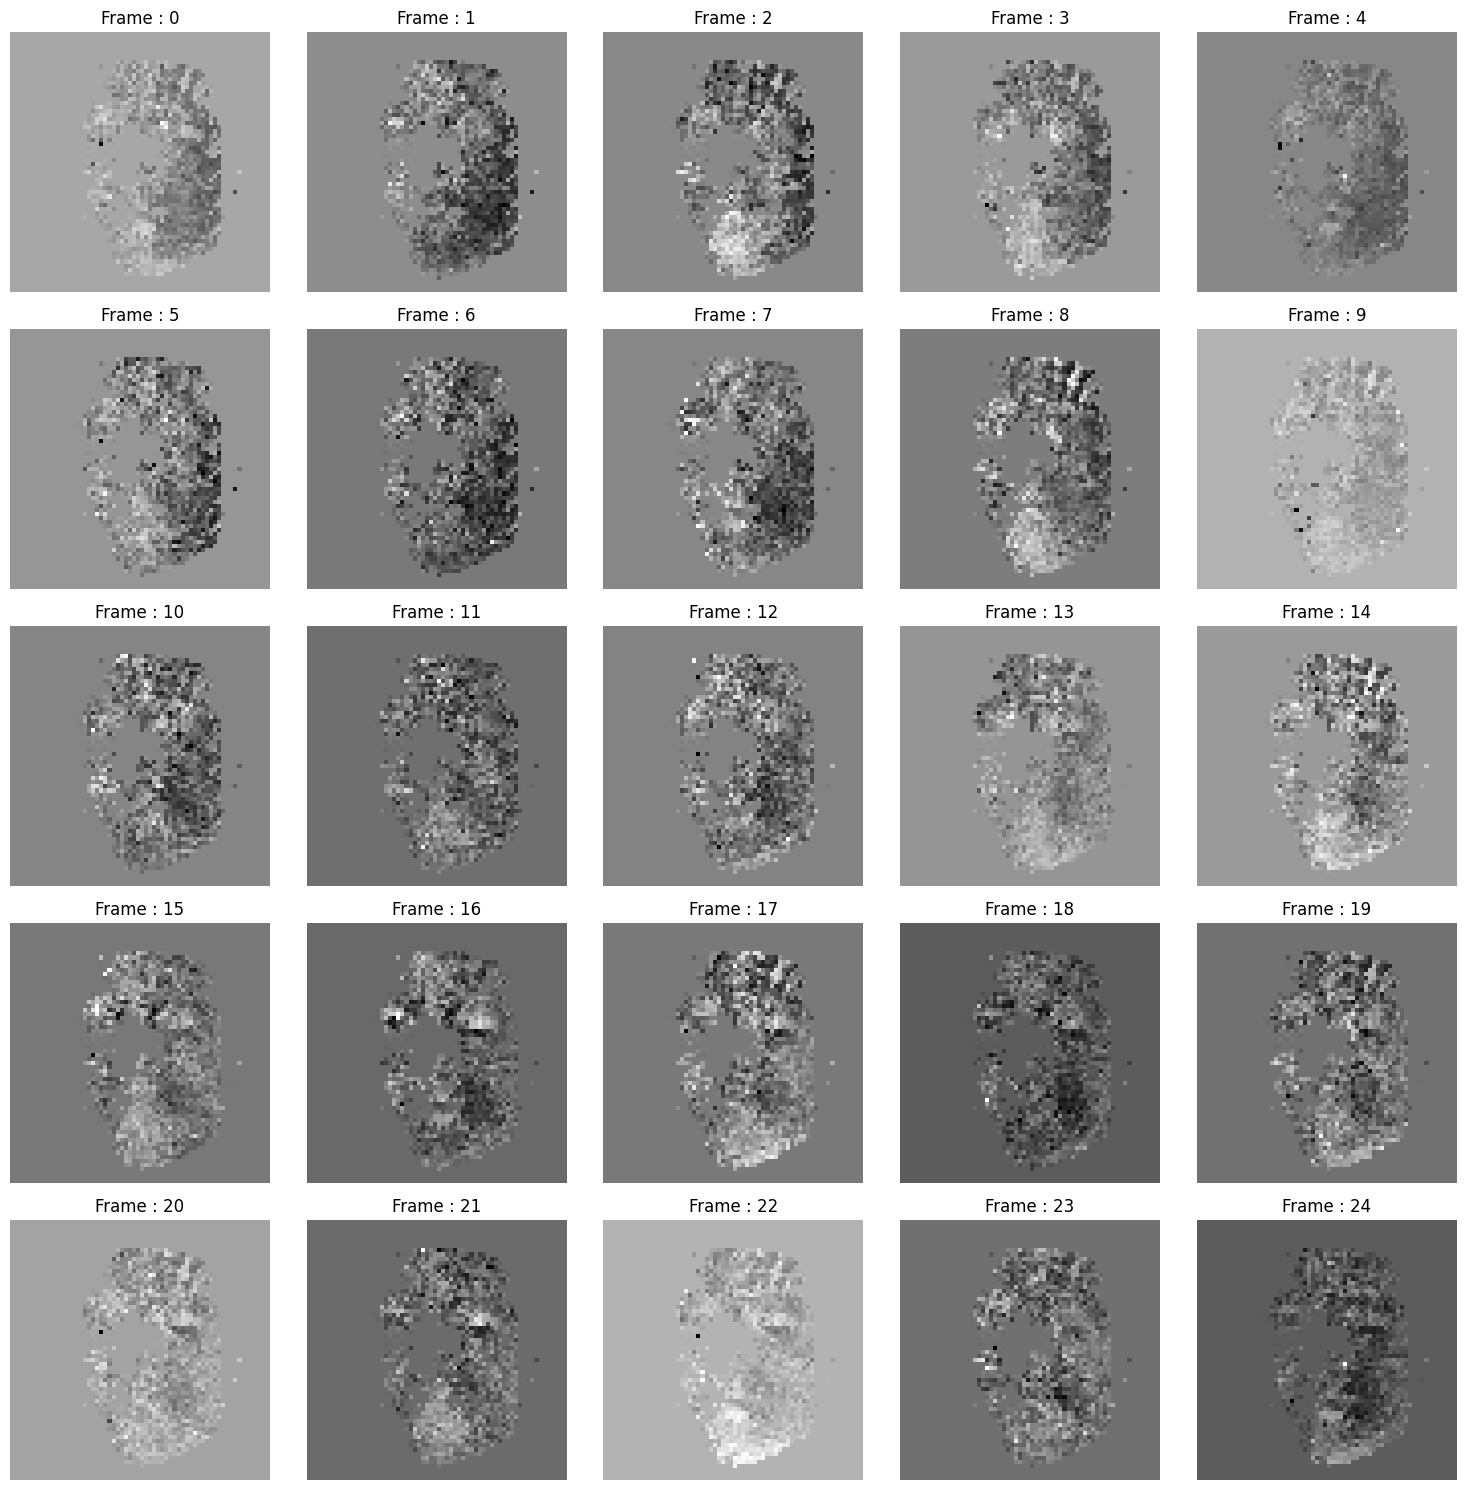

In [38]:
v1 = train_vid['B003']
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
axes = axes.flatten()

for i, f in enumerate(v1[1][25:50]):
        
    axes[i].imshow(f, cmap='gray')
    axes[i].set_title(f"Frame : {i}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()


In [39]:
print("=== Train Video Data 통계 ===")
for k in train_vid:
    video_array = train_vid[k]
    
    print(f"[Train Sub: {k}]")
    print(f"  - Shape: {video_array.shape}")
    print(f"  - Min: {np.min(video_array):.4f} | Max: {np.max(video_array):.4f}")
    print(f"  - Mean: {np.mean(video_array):.4f} | Std: {np.std(video_array):.4f}")
    print("-" * 30)

=== Train Video Data 통계 ===
[Train Sub: A006]
  - Shape: (125, 900, 64, 64)
  - Min: -29.5002 | Max: 29.9847
  - Mean: 0.0000 | Std: 0.5583
------------------------------
[Train Sub: A007]
  - Shape: (88, 900, 64, 64)
  - Min: -29.9833 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5817
------------------------------
[Train Sub: A008]
  - Shape: (76, 900, 64, 64)
  - Min: -29.6341 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.5395
------------------------------
[Train Sub: B001]
  - Shape: (135, 900, 64, 64)
  - Min: -29.8630 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5232
------------------------------
[Train Sub: B002]
  - Shape: (140, 900, 64, 64)
  - Min: -29.9831 | Max: 29.9840
  - Mean: -0.0000 | Std: 0.5660
------------------------------
[Train Sub: B003]
  - Shape: (127, 900, 64, 64)
  - Min: -29.6686 | Max: 29.9839
  - Mean: 0.0000 | Std: 0.5403
------------------------------
[Train Sub: B004]
  - Shape: (127, 900, 64, 64)
  - Min: -29.9829 | Max: 29.9840
  - Mean: 0.0001 | Std: 0.5576
---

In [40]:
print("\n=== Validation Video Data 통계 ===")
for j in valid_vid:
    video_array = valid_vid[j]
    
    print(f"[Valid Sub: {j}]")
    print(f"  - Shape: {video_array.shape}")
    print(f"  - Min: {np.min(video_array):.4f} | Max: {np.max(video_array):.4f}")
    print(f"  - Mean: {np.mean(video_array):.4f} | Std: {np.std(video_array):.4f}")
    print("-" * 30)


=== Validation Video Data 통계 ===
[Valid Sub: A004]
  - Shape: (135, 900, 64, 64)
  - Min: -29.4912 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.4833
------------------------------
[Valid Sub: A005]
  - Shape: (85, 900, 64, 64)
  - Min: -29.4527 | Max: 29.9840
  - Mean: 0.0000 | Std: 0.5446
------------------------------
